# 04. Loop와 종료 조건
## 학습 목표
- State 기반 반복과 종료 조건을 구현한다.
- `recursion_limit`이 무한 반복 방지용 실행 단계 제한임을 설명한다.

**핵심 개념**: Edge가 앞 Node로 돌아오면 Graph가 반복된다. 종료 판단은 업데이트된 State를 기준으로 한다. API 키는 필요하지 않다.

## 실행 전 예측
`count=0`, `target=3`일 때 `increment`는 몇 번 실행되고, 최종 `count`는 얼마일까?

In [ ]:
from pydantic import BaseModel
from langgraph.graph import START, END, StateGraph

# 상태 Schema 정의
# 유효성 검증 필요하면 BaseModel
# 유효성 검증이 필요없으면 TypedDict
class CounterState(BaseModel):
    count: int
    target: int

# Node 함수 정의
def increment(state: CounterState) -> dict:
    next_count = state.count + 1
    print("increment:", state.count, "→", next_count)
    return {"count": next_count}

# Node 함수 정의
def check(state: CounterState) -> dict:
    print("check: 현재", state.count, "/ 목표", state.target)
    return {"count": state.count}

# 조건 분기 함수 정의
def route_after_check(state: CounterState) -> str:
    return "done" if state.count >= state.target else "again"

# Graph builder 생성
builder = StateGraph(CounterState)
builder.add_node("increment", increment)
builder.add_node("check", check)

# Edge 연결
builder.add_edge(START, "increment")
builder.add_edge("increment", "check")
# 조건 분기 Edge 연결
builder.add_conditional_edges("check", route_after_check, {"again": "increment", "done": END})

# 
graph = builder.compile()

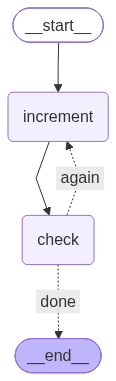

In [2]:
graph

In [3]:
# 두 Node가 세 차례씩 실행된다. 제한값은 충분한 여유를 둔다.
updates = list(graph.stream({"count": 0, "target": 3}, config={"recursion_limit": 10}, stream_mode="updates"))
print("Node 업데이트:", updates)
print("increment 실행 횟수:", sum("increment" in item for item in updates))

# 테스트
assert sum("increment" in item for item in updates) == 3

increment: 0 → 1
check: 현재 1 / 목표 3
increment: 1 → 2
check: 현재 2 / 목표 3
increment: 2 → 3
check: 현재 3 / 목표 3
Node 업데이트: [{'increment': {'count': 1}}, {'check': {'count': 1}}, {'increment': {'count': 2}}, {'check': {'count': 2}}, {'increment': {'count': 3}}, {'check': {'count': 3}}]
increment 실행 횟수: 3


In [ ]:
result = graph.invoke(
  {"count": 0, "target": 3}, config={"recursion_limit": 10}
  )
print("최종 State:", result)

# 테스트 
assert result["count"] == 3

increment: 0 → 1
check: 현재 1 / 목표 3
increment: 1 → 2
check: 현재 2 / 목표 3
increment: 2 → 3
check: 현재 3 / 목표 3
최종 State: {'count': 3, 'target': 3}


`recursion_limit`은 목표값 자체가 아니라 Graph 실행 단계의 상한이다. 제한을 너무 낮게 두면 정상 종료 전에 오류가 날 수 있다. 운영 코드에서는 목표 조건과 실행 제한을 함께 설계한다.

## 작은 수정 실습
`target=4`로 바꾸고 실행 횟수와 최종 State를 확인한다. 안전하게 `recursion_limit=12`를 사용한다.

## 이해 확인
1. `increment`가 반환한 `count`를 다음 `check`가 읽는 이유는 무엇인가?  
   **해설:** 업데이트가 Graph State에 반영된 뒤 다음 Node가 실행되기 때문이다.
2. 종료 조건을 항상 `again`으로 바꾸면 어떻게 되는가?  
   **해설:** Graph가 반복하다 `recursion_limit`에 도달하여 오류를 낸다. 실제로 무한 반복을 만들 필요는 없다.

**핵심 정리:** Loop는 같은 State의 최신 값을 읽으며, 명확한 종료 조건과 단계 제한이 필요하다.